In [1]:
import sys
import ee
import geemap

print("当前 Python：", sys.executable)
print("GEE 库版本：", ee.__version__)
print("geemap 版本：", geemap.__version__)

当前 Python： d:\anaconda\envs\geo311\python.exe
GEE 库版本： 1.7.50
geemap 版本： 0.37.2


In [ ]:
# 在浏览器中登录并授权
ee.Authenticate(auth_mode="localhost")

# 连接你的 Google Cloud 项目
ee.Initialize(project="valued-rigging-513206-g8")

# 验证能否访问 GEE 云端
print(ee.String("GEE 连接成功！").getInfo()) 


Successfully saved authorization token.
GEE 连接成功！


In [5]:
import ee
import geemap
import ipywidgets as widgets
from ipyleaflet import TileLayer, WidgetControl

# ===== 1. 认证并连接 GEE =====
ee.Authenticate(auth_mode="localhost")
ee.Initialize(project="valued-rigging-513206-g8")

print(ee.String("GEE 连接成功！").getInfo())

# ===== 2. 设置初步浏览范围 =====
# 顺序：最小经度、最小纬度、最大经度、最大纬度
# 此矩形用于定位，不是最终水库边界
overview_roi = ee.Geometry.Rectangle([
    33.0, 46.6,
    35.3, 48.0
])

# ===== 3. 创建交互式地图 =====
# center 的顺序：[纬度, 经度]
m = geemap.Map(
    center=[47.25, 34.15],
    zoom=8,
    height="650px",
    ee_initialize=False,     # 上面已经初始化
    search_ctrl=False,
    toolbar_ctrl=False,
    measure_ctrl=False,
    draw_ctrl=True,           # 保留矩形、多边形绘图工具
    layer_ctrl=True
)

# ===== 4. 替换为请求中文标注的底图 =====
chinese_basemap = TileLayer(
    url=(
        "https://mt1.google.com/vt/"
        "lyrs=m&hl=zh-CN&x={x}&y={y}&z={z}"
    ),
    name="中文底图",
    attribution="© Google",
    base=True,
    max_zoom=20
)

m.layers = (chinese_basemap,)

# ===== 5. 添加研究范围红色轮廓 =====
outline = ee.FeatureCollection([
    ee.Feature(overview_roi)
]).style(
    color="FF0000",
    fillColor="00000000",
    width=2
)

m.addLayer(outline, {}, "初步浏览范围")

# ===== 6. 添加中文说明和定位按钮 =====
info = widgets.HTML(
    value=(
        "<b>卡霍夫卡水库研究区</b><br>"
        "红框：初步浏览范围，并非水库边界。<br>"
        "可拖动、缩放，或使用左侧工具绘制区域。"
    )
)

back_button = widgets.Button(
    description="返回研究区",
    tooltip="将地图重新定位到卡霍夫卡水库附近"
)

def return_to_roi(_):
    m.center = [47.25, 34.15]
    m.zoom = 8

back_button.on_click(return_to_roi)

panel = widgets.VBox([info, back_button])

m.add(
    WidgetControl(
        widget=panel,
        position="topright"
    )
)

# ===== 7. 显示地图：保持为单元格最后一行 =====
m


GEE 连接成功！


Map(center=[47.25, 34.15], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

In [6]:
# 放大到原水库附近
m.center = [47.2, 34.0]
m.zoom = 9
m

Map(bottom=23269.0, center=[47.2, 34.0], controls=(WidgetControl(options=['position', 'transparent_bg'], posit…

In [7]:
import ee
import geemap

# ===== 1. 初步浏览范围，不是最终水库边界 =====
roi = ee.Geometry.Rectangle([33.0, 46.6, 35.3, 48.0])

# ===== 2. 去除云、云影等无效像元 =====
def mask_s2(image):
    scl = image.select("SCL")

    clear = (
        scl.neq(0)
        .And(scl.neq(1))
        .And(scl.neq(3))
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    return (
        image.updateMask(clear)
        .select(["B2", "B3", "B4", "B8", "B11"])
        .multiply(0.0001)
        .copyProperties(image, ["system:time_start"])
    )

# ===== 3. 筛选影像，打印日期，再进行合成 =====
def make_composite(start, end, label):
    collection = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(roi)
        .filterDate(start, end)
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 60))
    )

    dates = collection.aggregate_array("system:time_start").map(
        lambda t: ee.Date(t).format("YYYY-MM-dd")
    ).distinct().sort()

    info = ee.Dictionary({
        "count": collection.size(),
        "dates": dates
    }).getInfo()

    print(f"{label}：{info['count']} 个候选影像瓦片")
    print("候选观测日期：", ", ".join(info["dates"]))

    if info["count"] == 0:
        raise ValueError(f"{label}没有影像，请检查日期和筛选条件。")

    return collection.map(mask_s2).median().clip(roi)

# 日期筛选包含开始日期，不包含结束日期
before = make_composite(
    "2023-05-01", "2023-06-06", "溃决前"
)

after = make_composite(
    "2023-07-01", "2023-08-01", "溃决后"
)

# ===== 4. 两个时段使用相同的真彩色显示参数 =====
rgb_vis = {
    "bands": ["B4", "B3", "B2"],
    "min": 0,
    "max": 0.3
}

# 将去云后仍然缺测的位置显示为灰色
# 只处理显示图，不修改 before、after 分析影像
before_rgb = before.visualize(**rgb_vis).unmask(
    225, sameFootprint=False
).clip(roi)

after_rgb = after.visualize(**rgb_vis).unmask(
    225, sameFootprint=False
).clip(roi)

# ===== 5. 创建前后滑动对比地图 =====
comparison_map = geemap.Map(
    center=[47.2, 34.0],
    zoom=8,
    height="650px",
    ee_initialize=False,
    search_ctrl=False,
    toolbar_ctrl=False,
    draw_ctrl=False
)

comparison_map.split_map(
    left_layer=geemap.ee_tile_layer(
        before_rgb, {}, "溃决前"
    ),
    right_layer=geemap.ee_tile_layer(
        after_rgb, {}, "溃决后"
    ),
    left_label="溃决前：2023年5月1日—6月5日",
    right_label="溃决后：2023年7月1日—7月31日",
    layer_control=False
)

comparison_map

溃决前：81 个候选影像瓦片
候选观测日期： 2023-05-04, 2023-05-06, 2023-05-09, 2023-05-11, 2023-05-14, 2023-05-16, 2023-05-19, 2023-05-21, 2023-05-24, 2023-05-26, 2023-05-29, 2023-05-31, 2023-06-03, 2023-06-05
溃决后：66 个候选影像瓦片
候选观测日期： 2023-07-03, 2023-07-05, 2023-07-08, 2023-07-10, 2023-07-13, 2023-07-15, 2023-07-18, 2023-07-23, 2023-07-25, 2023-07-28, 2023-07-30


Map(center=[47.2, 34.0], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_out…

In [9]:
import ee
import geemap
import ipywidgets as widgets
from ipyleaflet import WidgetControl

# ===== 1. 检查前面的影像是否已生成 =====
if not all(
    name in globals()
    for name in ["before", "after", "roi"]
):
    raise RuntimeError(
        "请先运行生成 before、after 和 roi 的影像合成单元格。"
    )

# ===== 2. 计算 MNDWI =====
def calculate_mndwi(image):
    green = image.select("B3")
    swir = image.select("B11")
    denominator = green.add(swir)

    return (
        green.subtract(swir)
        .divide(denominator)
        .updateMask(denominator.abs().gt(1e-6))
        .rename("MNDWI")
        .clip(roi)
    )

before_mndwi = calculate_mndwi(before)
after_mndwi = calculate_mndwi(after)

# ===== 3. 两期使用完全相同的显示参数 =====
vis = {
    "min": -1,
    "max": 1,
    "palette": [
        "8C510A",  # 棕色：低值
        "DFC27D",
        "F5F5F5",  # 浅色：接近 0
        "67A9CF",
        "2166AC"   # 蓝色：高值
    ]
}

# ===== 4. 缺测区域显示为洋红色 =====
nodata_rgb = ee.Image.constant([255, 0, 255]).toUint8()

def display_mndwi(index):
    return (
        index.visualize(**vis)
        .unmask(nodata_rgb, sameFootprint=False)
        .clip(roi)
    )

# 注意：填色只作用于显示图，不修改原始指数
before_display = display_mndwi(before_mndwi)
after_display = display_mndwi(after_mndwi)

# ===== 5. 创建滑动对比地图 =====
mndwi_map = geemap.Map(
    center=[47.2, 34.0],
    zoom=8,
    height="650px",
    ee_initialize=False,
    search_ctrl=False,
    toolbar_ctrl=False,
    draw_ctrl=False
)

mndwi_map.split_map(
    left_layer=geemap.ee_tile_layer(
        before_display, {}, "溃决前 MNDWI"
    ),
    right_layer=geemap.ee_tile_layer(
        after_display, {}, "溃决后 MNDWI"
    ),
    left_label="溃决前 MNDWI：2023年5月1日—6月5日",
    right_label="溃决后 MNDWI：2023年7月1日—7月31日",
    layer_control=False
)

# ===== 6. 添加中文图例 =====
legend = widgets.HTML(value="""
<div style="background:white;padding:10px;color:#222;line-height:1.7;">
  <b>MNDWI（两期使用相同色带）</b><br>
  <div style="width:230px;height:14px;background:linear-gradient(
    to right,#8C510A,#DFC27D,#F5F5F5,#67A9CF,#2166AC
  );"></div>
  <div style="display:flex;justify-content:space-between;">
    <span>−1</span><span>0</span><span>+1</span>
  </div>
  <span style="display:inline-block;background:#FF00FF;
    width:14px;height:14px;"></span> 洋红色：缺测<br>
  浅色：接近 0 的有效指数值<br>
  研究框外显示底图
</div>
""")

mndwi_map.add(
    WidgetControl(widget=legend, position="topright")
)

mndwi_map

Map(center=[47.2, 34.0], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_out…

正在获取溃决前影像……
正在获取溃决后影像……
图片已保存到：F:\空间分析\对比图\卡霍夫卡水库_MNDWI溃决前后对比.png


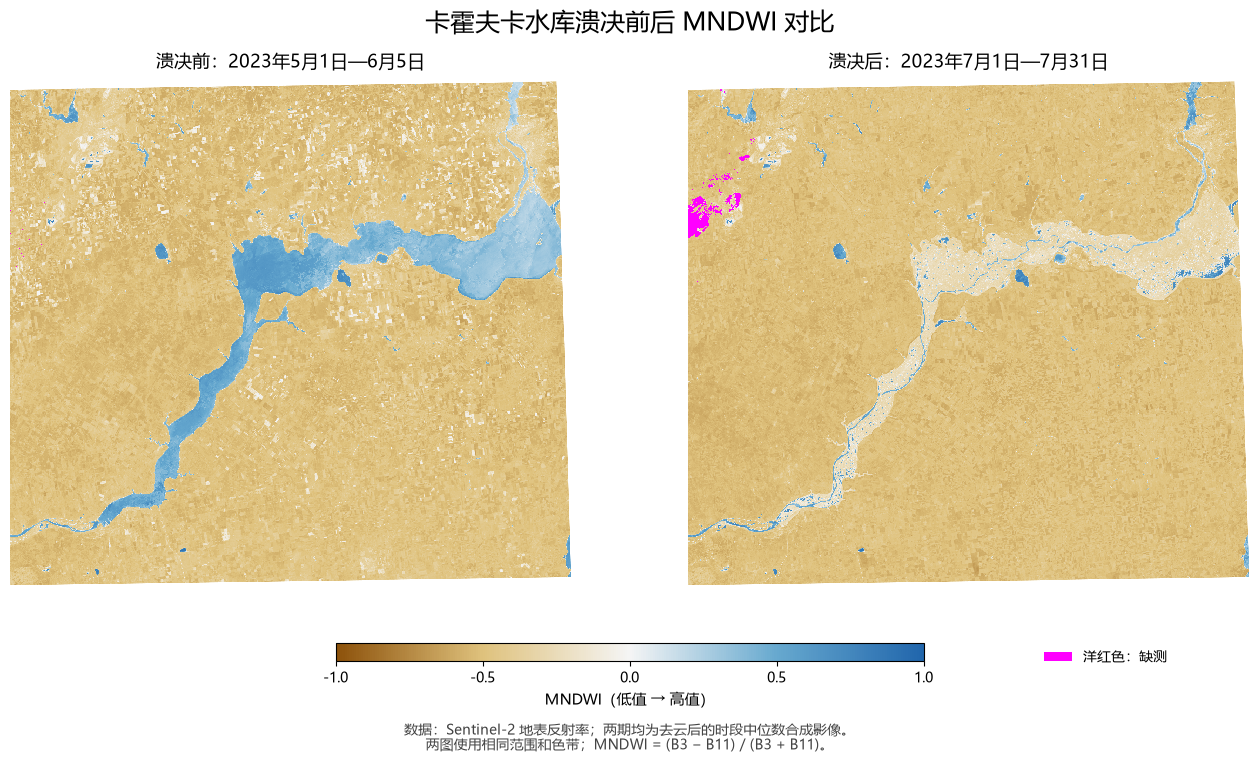

In [10]:
from io import BytesIO
from pathlib import Path
from datetime import datetime

import requests
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch

# ===== 1. 检查前面的可视化结果 =====
if not all(
    name in globals()
    for name in ["before_display", "after_display", "roi"]
):
    raise RuntimeError(
        "请先运行 MNDWI 可视化单元格，"
        "生成 before_display、after_display 和 roi。"
    )

# ===== 2. 设置导出路径 =====
output_dir = Path(r"F:\空间分析\对比图")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "卡霍夫卡水库_MNDWI溃决前后对比.png"

# 已有同名图片时，添加时间，避免覆盖
if output_file.exists():
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    output_file = output_dir / f"卡霍夫卡水库_MNDWI对比_{stamp}.png"

# ===== 3. 设置中文字体 =====
font_path = Path(r"C:\Windows\Fonts\msyh.ttc")

if font_path.exists():
    font_manager.fontManager.addfont(str(font_path))
    font_name = font_manager.FontProperties(
        fname=str(font_path)
    ).get_name()
    plt.rcParams["font.family"] = font_name
else:
    plt.rcParams["font.sans-serif"] = [
        "Microsoft YaHei", "SimHei", "DejaVu Sans"
    ]

plt.rcParams["axes.unicode_minus"] = False

# ===== 4. 获取两期已配色的 MNDWI 图片 =====
def download_preview(image):
    url = image.getThumbURL({
        "region": roi,
        "crs": "EPSG:32636",
        "dimensions": 1600,
        "format": "png"
    })

    response = requests.get(url, timeout=(15, 180))
    response.raise_for_status()

    with Image.open(BytesIO(response.content)) as opened:
        rgba = opened.convert("RGBA")

    # 范围外透明部分设为白色，保留内部洋红色缺测区
    background = Image.new(
        "RGBA", rgba.size, (255, 255, 255, 255)
    )

    return Image.alpha_composite(
        background, rgba
    ).convert("RGB")

print("正在获取溃决前影像……")
left_image = download_preview(before_display)

print("正在获取溃决后影像……")
right_image = download_preview(after_display)

# ===== 5. 创建并排对比图 =====
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 8),
    facecolor="white"
)

fig.subplots_adjust(
    left=0.025,
    right=0.975,
    top=0.87,
    bottom=0.24,
    wspace=0.04
)

titles = [
    "溃决前：2023年5月1日—6月5日",
    "溃决后：2023年7月1日—7月31日"
]

for ax, picture, title in zip(
    axes, [left_image, right_image], titles
):
    ax.imshow(picture, interpolation="nearest")
    ax.set_title(title, fontsize=13, pad=10)
    ax.axis("off")

fig.suptitle(
    "卡霍夫卡水库溃决前后 MNDWI 对比",
    fontsize=18,
    y=0.96
)

# ===== 6. 添加统一色标 =====
palette = [
    "#8C510A",
    "#DFC27D",
    "#F5F5F5",
    "#67A9CF",
    "#2166AC"
]

cmap = LinearSegmentedColormap.from_list(
    "mndwi_colors", palette
)

colorbar_ax = fig.add_axes([
    0.29, 0.145, 0.42, 0.023
])

colorbar = fig.colorbar(
    ScalarMappable(
        norm=Normalize(vmin=-1, vmax=1),
        cmap=cmap
    ),
    cax=colorbar_ax,
    orientation="horizontal",
    ticks=[-1, -0.5, 0, 0.5, 1]
)

colorbar.set_label(
    "MNDWI（低值 → 高值）",
    fontsize=11
)

# ===== 7. 添加缺测说明 =====
fig.legend(
    handles=[
        Patch(
            facecolor="#FF00FF",
            label="洋红色：缺测"
        )
    ],
    loc="center",
    bbox_to_anchor=(0.84, 0.15),
    frameon=False
)

# ===== 8. 添加数据说明 =====
fig.text(
    0.5,
    0.035,
    "数据：Sentinel-2 地表反射率；"
    "两期均为去云后的时段中位数合成影像。\n"
    "两图使用相同范围和色带；"
    "MNDWI = (B3 − B11) / (B3 + B11)。",
    ha="center",
    fontsize=10,
    color="#444444"
)

# ===== 9. 保存并显示 =====
fig.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print(f"图片已保存到：{output_file.resolve()}")

plt.show()